# Active subspaces of a BISON fuel-performance simulation: pellet-cladding mechanical interaction during a power ramp

Stored data from

M. I. Radaideh and T. Kozlowski, *Surrogate modeling of advanced computer simulations using deep Gaussian
processes*, Reliability Engineering & System Safety 195:106731, 2020.
[doi:10.1016/j.ress.2019.106731](https://doi.org/10.1016/j.ress.2019.106731)

Department of Nuclear, Plasma, and Radiological Engineering, University of Illinois at Urbana-Champaign,
Urbana, Illinois 61801, USA

Page, table and equation numbers below are those of the accepted manuscript of the article (33 pages); the
reference is the version of record. The 400 BISON runs are those distributed with the pyMAISE package
(pyMAISE 0.0.2, files `fp_inp.csv` and `fp_out.csv`, Apache License 2.0), whose documentation states that they
come from this article.

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac

SEED = 2020                      # the only seed: every bootstrap and permutation below draws from it
t_start = time.perf_counter()
warnings.simplefilter('ignore', ac.ValidityWarning)

## Summary

Radaideh and Kozlowski ran the BISON fuel-performance code on Case 1 of the OECD/NEA pellet-cladding mechanical
interaction (PCMI) benchmark, a beginning-of-life power ramp of a 10-pellet PWR rod, with 13 fabrication, power
and coolant parameters drawn from independent normal laws, and recorded four scalar outputs; the 400 runs
distributed with pyMAISE reproduce the paper's output statistics (p. 26), and the paper trained and validated
its surrogate on 300 runs (Table 3, p. 18). The notebook estimates active subspaces of the four outputs from the
400 stored runs with the global quadratic estimator (QPHD), the inputs scaled by their sample standard
deviations. The fission gas produced, the maximum fuel centreline temperature and the radial cladding
displacement are one-dimensional to within the noise of the fit ($\lambda_1/\lambda_2$ = 2919.7, 1210.1 and
1873.4; a quadratic in one active variable has leave-one-out $R^2$ 0.9994, 0.9973 and 0.9978), with the
centreline temperature driven by the linear heat rate, the fuel porosity and the cladding surface temperature,
and the fission gas exactly proportional to pellet height times linear heat rate. The maximum fuel surface
temperature is the exception: $\lambda_1/\lambda_2$ = 19.0 and $\lambda_2/\lambda_3$ = 6.84, a second direction
(pellet height) is resolved against a noise null, and a quadratic in two active variables has LOO $R^2$ 0.9401.
The pellet height acts on both temperatures through a non-smooth term, a raised window of pellet heights whose
lower edge also depends on porosity, power and cladding temperature, that no quadratic captures: a fit linear in
the other 12 inputs plus a piecewise-linear function of the pellet height raises the LOO $R^2$ of the surface
temperature from 0.9181 to 0.9839 (centreline 0.9967 to 0.9988); its cause in the BISON runs is not known.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Without gradients the matrix can be estimated from values: the global quadratic estimator (QPHD) fits
a quadratic $q$ by least squares and uses $\mathbf{C} = E[\nabla q\, \nabla q^\top]$. See P. G. Constantine,
*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015,
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Simulator.** BISON is the finite-element nuclear fuel performance code of Idaho National Laboratory
(Williamson et al. 2012, reference list below), which couples heat conduction in the fuel and cladding,
quasi-static mechanics, gap heat transfer and contact, and fuel behaviour models (fission gas release,
swelling, densification). In its textbook form the thermal problem is

$$\rho c_p \frac{\partial T}{\partial t} - \nabla\cdot\big(k(T, \dots)\nabla T\big) = \dot q ,$$

with the volumetric heat source $\dot q$ set by the linear heat rate, and a gap conductance between pellet and
cladding that depends on the gap width, the gas and the surface roughnesses. This equation is given for
orientation only: the paper gives no BISON equations (Sect. 3.4, pp. 15–16, describes BISON in words, "the
fully-coupled equations of thermomechanics and species diffusion").

**Problem** (Sect. 3.4, p. 15). Case 1 of the PCMI benchmark: a
beginning-of-life ramp of a 10-pellet pressurized water reactor (PWR) fuel rod to an average linear heat rate
of 40 kW/m. The inner and outer cladding diameters are reduced so that fuel-cladding contact occurs during the
ramp; the axial power and rod surface temperature profiles are uniform, the surface at 330 °C. The benchmark
is the OECD/NEA PCMI benchmark of Rossiter et al. (2016).

**Inputs** ($m = 13$; Sect. 3.4 and Table 2, pp. 15–16). "The selected uncertain parameters are all sampled
independently from normal distribution with uncertainty values shown in Table 2. The nominal values are taken
from the benchmark. The uncertainties in Table 2 are expressed in relative form (i.e. ratio of standard
deviation to nominal value)" (p. 15). Table 2 gives relative standard deviations from 0.1 % to 15 %; the
nominal values are not printed. Column names and units are those of the pyMAISE files. The pyMAISE
documentation's "uniformly randomly sampled independently within their uncertainty bounds" is an error of that
documentation: the paper says normal, and the stored samples are normal (checks below). `ax_pow` is the
paper's linear heat rate (LHR, $q'$), stored as a factor of its nominal: it is the only 2.0 % input of
Table 2, and the paper's 13 inputs include "inlet temperature, system pressure, and linear heat rate (LHR)"
(p. 15). The notebook uses the sample mean and standard deviation of each input as its normal law; the
next cells compare the sample relative standard deviations with Table 2.

**Quantities of interest** (one run each; Sect. 3.4, p. 16, "over the last time step only"): `fis_gas_produced`, fission gas production (mol);
`max_fuel_centerline_temp`, maximum fuel centreline temperature (K); `max_fuel_surface_temp`, maximum fuel
surface temperature (K); `radial_clad_dia`, radial cladding diameter displacement after irradiation (m).
The main analysis is for the centreline temperature; all four outputs are analysed the same way.

In [2]:
# The 13 inputs in the column order of bison_fp_inputs.csv: name and unit as in the pyMAISE files,
# description as in Table 2 (p. 16) of the paper, and Table 2's relative standard deviation.
INPUTS = [
    ('fuel_dens', 'fuel density', 'kg/m3'),
    ('porosity', 'fuel porosity', '1'),
    ('clad_thick', 'cladding thickness', 'm'),
    ('pellet_OD', 'pellet outer diameter', 'm'),
    ('pellet_h', 'pellet height', 'm'),
    ('gap_thick', 'pellet-cladding gap thickness', 'm'),
    ('inlet_T', 'coolant inlet temperature', 'K'),
    ('enrich', 'U-235 enrichment', '1'),
    ('rough_fuel', 'fuel surface roughness', 'm'),
    ('rough_clad', 'cladding surface roughness', 'm'),
    ('ax_pow', 'linear heat rate (factor of nominal)', '1'),
    ('clad_T', 'cladding surface temperature', 'K'),
    ('pressure', 'coolant pressure', 'Pa'),
]
QOIS = [
    ('fis_gas_produced', 'fission gas produced', 'mol'),
    ('max_fuel_centerline_temp', 'maximum fuel centerline temperature', 'K'),
    ('max_fuel_surface_temp', 'maximum fuel surface temperature', 'K'),
    ('radial_clad_dia', 'radial cladding diameter displacement', 'm'),
]
NAMES = [n for n, _, _ in INPUTS]
TABLE2 = {'fuel_dens': 0.002, 'porosity': 0.15, 'clad_thick': 0.005, 'pellet_OD': 0.001, 'pellet_h': 0.044,
          'gap_thick': 0.005, 'inlet_T': 0.005, 'enrich': 0.001, 'rough_fuel': 0.10, 'rough_clad': 0.10,
          'ax_pow': 0.02, 'clad_T': 0.01, 'pressure': 0.01}     # sd / nominal, Table 2, p. 16
REL_T2 = np.array([TABLE2[n] for n in NAMES])
m = len(NAMES)

## Load the data

Two CSV files, converted losslessly by `convert_data.py` from the pyMAISE 0.0.2 wheel (the same bytes as the
files of Zenodo record 20140559 that later pyMAISE versions download): the 13 inputs in physical units, and
the four outputs of the same 400 runs, row by row.

In [3]:
def read(path):
    """Values and the column names / units from the second '#' line of one of this data set's CSVs."""
    with open(path) as fh:
        fh.readline()
        cols = fh.readline()[2:].strip().split(',')
    return (np.loadtxt(path, delimiter=','), [c.split(' [')[0] for c in cols],
            [c.split(' [')[1].rstrip(']') for c in cols])


X, xnames, xunits = read('bison_fp_inputs.csv')        # 400 x 13, physical units
F, fnames, funits = read('bison_fp_outputs.csv')       # 400 x 4
assert xnames == NAMES and xunits == [u for _, _, u in INPUTS]
assert fnames == [q for q, _, _ in QOIS]
M = X.shape[0]
print('inputs', X.shape, ' outputs', F.shape)

inputs (400, 13)  outputs (400, 4)


In [4]:
mu, sd = X.mean(axis=0), X.std(axis=0, ddof=1)
se = 1 / np.sqrt(2 * (M - 1))                   # approximate standard error of sd / sigma for normal samples
zt2 = (sd / np.abs(mu) / REL_T2 - 1) / se
print(f"{'input':11s} {'unit':6s} {'mean':>11s} {'sd':>10s} {'sd/mean':>8s} {'Table 2':>7s} {'(z)':>6s} "
      f"{'min':>11s} {'max':>11s}")
for i, (n, d, u) in enumerate(INPUTS):
    print(f'{n:11s} {u:6s} {mu[i]:11.5g} {sd[i]:10.4g} {sd[i] / abs(mu[i]):8.2%} {REL_T2[i]:7.1%} {zt2[i]:+6.2f} '
          f'{X[:, i].min():11.5g} {X[:, i].max():11.5g}')
print(f'largest |sample sd/mean - Table 2| in standard errors: {np.abs(zt2).max():.2f}')
zt = np.abs(X - mu) / (REL_T2 * np.abs(mu))
print('largest |x - mean| in Table 2 standard deviations (inputs above 3.2): '
      + ', '.join(f'{NAMES[i]} {zt[:, i].max():.2f}' for i in np.argsort(-zt.max(axis=0)) if zt[:, i].max() > 3.2))
print()
for j, (q, d, u) in enumerate(QOIS):
    print(f'{q:25s} {u:4s} mean {F[:, j].mean():.5g}  sd {F[:, j].std(ddof=1):.4g}  '
          f'range [{F[:, j].min():.5g}, {F[:, j].max():.5g}]')
print()
for lab, rows in (('all 400 rows', slice(None)), ('first 300 rows', slice(0, 300)), ('last 300 rows', slice(100, 400))):
    G = F[rows]
    print(f'{lab:15s} mean (sd/mean): ' + ', '.join(f'{G[:, j].mean():.5g} ({G[:, j].std(ddof=1) / G[:, j].mean():.2%})'
                                                   for j in range(4)))

input       unit          mean         sd  sd/mean Table 2    (z)         min         max
fuel_dens   kg/m3        10456       20.1    0.19%    0.2%  -1.10       10396       10522
porosity    1         0.046896   0.007236   15.43%   15.0%  +0.81    0.021141    0.068638
clad_thick  m       0.00056976  2.978e-06    0.52%    0.5%  +1.28  0.00056167  0.00057653
pellet_OD   m        0.0040961  4.211e-06    0.10%    0.1%  +0.79   0.0040824   0.0041081
pellet_h    m         0.013762  0.0005999    4.36%    4.4%  -0.26    0.012056    0.015709
gap_thick   m       1.9008e-05  9.633e-08    0.51%    0.5%  +0.38    1.88e-05    1.93e-05
inlet_T     K           292.31      1.433    0.49%    0.5%  -0.56      287.52       296.2
enrich      1         0.044872  4.527e-05    0.10%    0.1%  +0.25    0.044749     0.04501
rough_fuel  m       1.7887e-06  1.817e-07   10.16%   10.0%  +0.44    1.26e-06    2.31e-06
rough_clad  m       3.9874e-07  3.759e-08    9.43%   10.0%  -1.62    2.89e-07    5.19e-07
ax_pow    

The relative spreads are small (0.10–15.43 % of the mean; largest for porosity and the two roughnesses), so the
model is probed in a narrow region around one nominal design. Every sample relative standard deviation agrees
with Table 2 (p. 16) to within 1.82 standard errors (largest for `ax_pow`, 2.13 % against 2.0 %), so the sample
moments are a fair stand-in for the declared normal laws, whose nominal values the paper does not print. The
paper says that ±3σ "is the support of the samples used to train the DeepGP models" (p. 27); measured with the
Table 2 standard deviation about the sample mean, the stored samples reach 3.66σ (porosity), 3.64σ (`ax_pow`)
and 3.34σ (`pellet_OD`), so they are not truncated at ±3σ (samples of 400 normal values are expected to reach
about 3σ). The sample mean of the cladding surface temperature, 603.62 K, is the benchmark's 330 °C (603.15 K).
`enrich` is stored as a fraction (0.044872) and `ax_pow`, the linear heat rate, as a factor of mean 1.0014.

**Output statistics.** The paper gives (p. 26) 3.1e-5 mol (4.8 %), 1591.6 K (2.4 %), 701.8 K (1.1 %) and
1.92e-5 m (4.2 %) for the four outputs. All 400 stored rows give 3.1069e-05 (4.80 %), 1591.6 (2.36 %), 701.75
(1.11 %) and 1.9234e-05 (4.20 %), equal at the printed precision: strong evidence that these are the paper's runs.
The paper's DeepGP used 200 training and 100 validation runs (Table 3, p. 18), so 300, not 400; which 300 is
not stated, and subsets do not settle it (the last 300 rows give 1591.6 K and 701.82 K, the first 300 give
1591.4 K and 701.95 K).

### Design, and checks of the data

The cell tests the stored inputs against a uniform law (Kolmogorov–Smirnov on each input's sample range) and
a normal law (Shapiro–Wilk, kurtosis, share within one standard deviation), checks independence, and records
the stored precision of the inputs and outputs.

In [5]:
print('duplicate input rows:', M - len(np.unique(X, axis=0)))
Z0 = (X - mu) / sd
kurt = stats.kurtosis(X, axis=0, fisher=False)
in1 = np.mean(np.abs(Z0) < 1, axis=0)
ks_u = [stats.kstest((X[:, i] - X[:, i].min()) / np.ptp(X[:, i]), 'uniform').pvalue for i in range(m)]
sw = [stats.shapiro(X[:, i]).pvalue for i in range(m)]
nd = [len(np.unique(X[:, i])) for i in range(m)]
print(f"\n{'input':11s} {'kurtosis':>8s} {'|z|<1':>6s} {'KS p, uniform':>13s} {'Shapiro p':>9s} {'distinct':>8s}")
for i, n in enumerate(NAMES):
    print(f'{n:11s} {kurt[i]:8.2f} {in1[i]:6.2f} {ks_u[i]:13.1e} {sw[i]:9.3f} {nd[i]:8d}')
print(f'\nkurtosis {kurt.min():.2f}-{kurt.max():.2f} (normal 3, uniform 1.8); share within one sd '
      f'{in1.min():.2f}-{in1.max():.2f} (normal 0.68, uniform 0.58); largest KS p against a uniform law '
      f'{max(ks_u):.1e}')
R = np.corrcoef(X.T)
iu = np.triu_indices(m, 1)
print(f'largest |input correlation| {np.abs(R[iu]).max():.3f}; pairs with |r| > 0.1: '
      f'{int(np.sum(np.abs(R[iu]) > 0.1))} of {len(iu[0])}')
rnull = np.array([np.abs(np.corrcoef(np.random.default_rng(SEED + k).standard_normal((M, m)).T)[iu]).max()
                  for k in range(200)])
print(f'largest |r| among 78 pairs of independent normal samples of size {M}: '
      f'median {np.median(rnull):.3f}, 95% quantile {np.quantile(rnull, 0.95):.3f}')
ig = NAMES.index('gap_thick')
vals, counts = np.unique(X[:, ig], return_counts=True)
print('\ngap_thick: stored values (m) and counts: '
      + ', '.join(f'{v:.3g} ({c})' for v, c in zip(vals, counts)) + f'; spacing / sd = {1e-7 / sd[ig]:.2f}'
      + f' (sample sd), {1e-7 / (REL_T2[ig] * mu[ig]):.2f} (Table 2 sd)')
print('\noutputs: distinct values, and the variance of a uniform rounding error of half the stored step '
      'as a share of the variance')
for j, (q, _, u) in enumerate(QOIS):
    v = np.unique(F[:, j])
    step = np.min(np.diff(v))
    print(f'  {q:25s} {len(v):4d} distinct; smallest step {step:.3g} {u}; '
          f'step^2/12 / variance = {step**2 / 12 / F[:, j].var(ddof=1):.1e}')
ic, isf = 1, 2
print('\ncentreline above surface temperature in every row:', bool(np.all(F[:, ic] > F[:, isf])),
      '; displacement positive in every row:', bool(np.all(F[:, 3] > 0)))

duplicate input rows: 0

input       kurtosis  |z|<1 KS p, uniform Shapiro p distinct
fuel_dens       3.05   0.67       1.5e-18     0.669       91
porosity        3.07   0.68       1.3e-23     0.827      397
clad_thick      2.55   0.65       3.7e-14     0.073      340
pellet_OD       3.07   0.70       1.3e-19     0.984      157
pellet_h        2.95   0.69       4.6e-19     0.982      361
gap_thick       2.85   0.68       9.1e-42     0.000        6
inlet_T         3.09   0.67       1.2e-22     0.282      284
enrich          2.72   0.67       6.6e-16     0.544      165
rough_fuel      2.92   0.69       1.3e-13     0.755       82
rough_clad      2.96   0.69       1.4e-18     0.963      144
ax_pow          3.00   0.68       4.6e-27     0.432      335
clad_T          2.74   0.66       2.9e-13     0.462      368
pressure        3.41   0.70       5.3e-19     0.266      278

kurtosis 2.55-3.41 (normal 3, uniform 1.8); share within one sd 0.65-0.70 (normal 0.68, uniform 0.58); largest KS p agai

**The inputs are normal, not uniform.** Kurtosis 2.55–3.41 (3 for a normal, 1.8 for a uniform law), 0.65–0.70
of each sample within one standard deviation (0.68 normal, 0.58 uniform), and the largest Kolmogorov–Smirnov
p-value against a uniform law on the sample range is 2.9e-13; Shapiro–Wilk does not reject normality for
12 of the 13 inputs (p ≥ 0.073). The exception is `gap_thick`, which is stored rounded to three significant
digits: 6 distinct values, a spacing of 1.04 sample standard deviations (1.05 Table 2 standard deviations), so its stored value is a coarse
quantization of whatever value the run used (not known), and its Shapiro–Wilk test is meaningless. The
largest input correlation, 0.143, is what independent samples give (median 0.131, 95 % quantile 0.165 of the
largest of 78 correlations), so the inputs are treated as independent normals. No input row is repeated.

This agrees with the paper ("sampled independently from normal distribution", p. 15); the pyMAISE
documentation's "uniformly randomly sampled" is an error of that documentation. The sampler (Monte Carlo or a
stratified normal design) and its seed are not stated and cannot be told from 400 rows.

**Outputs.** The two temperatures are stored with 400 distinct values each; `fis_gas_produced` (73 distinct)
and `radial_clad_dia` (44 distinct) are stored to three significant digits, a rounding whose variance is
3.7e-04 and 1.3e-03 of the output variance: a noise floor that limits any fit of those two outputs to
$R^2 \approx 0.9996$ and $0.9987$. The centreline temperature is above the surface temperature and the
displacement is positive in every row. **Rule: all 400 rows are used.**

## Estimate the active subspace

**Scaling.** Each input is scaled by its own sample standard deviation: `ac.Gaussian(mean, sd**2)` with the
sample means and standard deviations of the 400 rows, so the normalized inputs are
$z_i = (x_i - \bar x_i)/s_i$, independent and approximately standard normal. X is passed in physical units and
v1 normalizes once. The paper's declared law is normal with the Table 2 relative standard deviation times the
benchmark nominal (p. 15), and the nominal is not printed; the sample moments, which agree with Table 2 (above),
stand in for it. This is the notebook's choice.

**Estimator.** There are no gradients: BISON was run as a black box, and it cannot be rerun here. With
$M = 400$ runs, a full quadratic in 13 inputs ($(m+1)(m+2)/2 = 105$ coefficients) can be fitted by least
squares, and QPHD is the estimator for values on a Gaussian space: it fits the quadratic and averages
$\nabla q\,\nabla q^\top$ over the standard normal density. The bootstrap has 500 replicates (`SEED`). The cell
also reports the in-sample and exact leave-one-out (LOO) $R^2$ of the linear and quadratic fits in all 13
inputs, and orients $w_1$ and $w_2$ so that each output increases along them (`ac.orient(by='covariance')`; the
paper has no eigenvector figure to match).

In [6]:
space = ac.Gaussian(mu, sd**2, names=NAMES)     # independent normals with the sample mean and sd
Z = space.to_normalized(X)                         # z_i = (x_i - mean_i) / sd_i
print('normalized = (x - mean) / sd:', bool(np.allclose(Z, (X - mu) / sd)),
      '; normalized sample sd: ', np.round(Z.std(axis=0, ddof=1), 12).min(), '-', np.round(Z.std(axis=0, ddof=1), 12).max())


def design(Zs, degree):
    """Columns 1, z (degree 1) and also all squares and cross products z_j z_k, j <= k (degree 2)."""
    cols = [np.ones(len(Zs)), *Zs.T]
    if degree == 2:
        J, K = np.triu_indices(Zs.shape[1])
        cols += list((Zs[:, J] * Zs[:, K]).T)
    return np.column_stack(cols)


def fit_r2(A, f):
    """In-sample and exact leave-one-out R^2 of the least-squares fit of f on the columns of A."""
    Q, _ = np.linalg.qr(A)
    h = np.sum(Q**2, axis=1)
    r = f - Q @ (Q.T @ f)
    tss = np.sum((f - f.mean())**2)
    return 1 - r @ r / tss, 1 - np.sum((r / (1 - h))**2) / tss


A1, A2 = design(Z, 1), design(Z, 2)
print(f'linear fit: {A1.shape[1]} coefficients; quadratic fit: {A2.shape[1]} coefficients; M = {M}')

normalized = (x - mean) / sd: True ; normalized sample sd:  1.0 - 1.0
linear fit: 14 coefficients; quadratic fit: 105 coefficients; M = 400


In [7]:
NBOOT = 500
subs, FITS, UNALIGNED = {}, {}, []
for j, (q, _, _) in enumerate(QOIS):
    f = F[:, j]
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ac.AccuracyWarning)
        s = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', n=2, nboot=NBOOT,
                               bootstrap_vectors=2, rng=SEED, qoi=q)
    if any('unaligned_replicates' in str(w.message) for w in caught):
        UNALIGNED.append(q)
    subs[q] = ac.orient(s, by='covariance', X=X, f=f, columns=2)    # f increases along w1 and w2
    FITS[q] = fit_r2(A1, f) + fit_r2(A2, f)
print(f"{'QoI':25s} {'lin R2':>7s} {'lin LOO':>7s} {'quad R2':>7s} {'quad LOO':>8s} "
      f"{'l1/l2':>8s} {'95% boot':>17s} {'l2/l3':>6s} {'l1 share':>8s}")
for q, _, _ in QOIS:
    s = subs[q]
    ev, be = s.eigenvalues, s.bootstrap_eigenvalues
    ci = np.percentile(be[:, 0] / be[:, 1], [2.5, 97.5])
    print(f'{q:25s} {FITS[q][0]:7.4f} {FITS[q][1]:7.4f} {FITS[q][2]:7.4f} {FITS[q][3]:8.4f} '
          f'{ev[0] / ev[1]:8.1f} [{ci[0]:7.1f}, {ci[1]:7.1f}] {ev[1] / ev[2]:6.2f} {ev[0] / ev.sum():8.4f}')
print('LOO R^2 gain of the quadratic over the linear fit: '
      + ', '.join(f'{q} {FITS[q][3] - FITS[q][1]:+.4f}' for q, _, _ in QOIS))
print('outputs whose bootstrap replicates of w2 are poorly aligned with w2 (v1 AccuracyWarning):', UNALIGNED)

QoI                        lin R2 lin LOO quad R2 quad LOO    l1/l2          95% boot  l2/l3 l1 share
fis_gas_produced           0.9993  0.9992  0.9997   0.9995   2919.7 [ 1919.6,  3485.2]   6.56   0.9994
max_fuel_centerline_temp   0.9969  0.9967  0.9985   0.9971   1210.1 [  419.6,  1240.3]   2.01   0.9979
max_fuel_surface_temp      0.9236  0.9181  0.9577   0.9197     19.0 [    8.0,    26.0]   6.84   0.9170
radial_clad_dia            0.9969  0.9966  0.9986   0.9973   1873.4 [  675.0,  1637.4]   1.80   0.9983
LOO R^2 gain of the quadratic over the linear fit: fis_gas_produced +0.0003, max_fuel_centerline_temp +0.0004, max_fuel_surface_temp +0.0016, radial_clad_dia +0.0007
outputs whose bootstrap replicates of w2 are poorly aligned with w2 (v1 AccuracyWarning): ['max_fuel_centerline_temp', 'radial_clad_dia']


All four outputs are almost linear in the inputs over this narrow region: the linear fit in 13 inputs has LOO
$R^2$ 0.9992, 0.9967 and 0.9966 for the fission gas, the centreline temperature and the displacement, and the
105-term quadratic adds at most 0.0007 to the LOO $R^2$ (0.9995, 0.9971, 0.9973). The surface temperature is
different: LOO $R^2$ 0.9181 linear and 0.9197 quadratic, against an in-sample 0.9577 for the quadratic, so the
extra 91 quadratic terms mostly fit noise there (LOO gain +0.0016); a later cell shows that most of what is
left is a non-smooth function of the pellet height.

The first eigenvalue carries 0.9994, 0.9979 and 0.9983 of the trace for the three near-linear outputs
($\lambda_1/\lambda_2$ = 2919.7, 1210.1, 1873.4), and 0.9170 for the surface temperature
($\lambda_1/\lambda_2$ = 19.0, $\lambda_2/\lambda_3$ = 6.84). The bootstrap intervals of $\lambda_1/\lambda_2$
([419.6, 1240.3] for the centreline temperature, [8.0, 26.0] for the surface temperature) lie mostly below the
full-sample values, as expected of a ratio whose denominator is a noisy small eigenvalue. For the centreline
temperature and the displacement the bootstrap replicates of $w_2$ are poorly aligned with $w_2$ (a v1
AccuracyWarning), i.e. $w_2$ is not determined.

**Is there a second direction?** A small $\lambda_2$ can come from noise alone: QPHD fits a quadratic to
noisy values, and the noise makes $\nabla q$ vary in every direction. The next cell builds a null with exactly
one direction: the linear fit of each output plus a random permutation of its residuals (200 replicates), and
compares the observed $\lambda_2/\lambda_1$ with the null distribution.

In [8]:
# Null for the second direction: the linear fit plus permuted linear residuals is exactly linear (one
# direction) with noise of the observed size; QPHD on such data gives lambda2/lambda1 from noise alone.
rng = np.random.default_rng(SEED)
Q1, _ = np.linalg.qr(A1)
NNULL = 200
NULL = {}
print(f"{'QoI':25s} {'l2/l1':>9s} {'null 95%':>9s} {'null max':>9s}  above every null replicate?")
for j, (q, _, _) in enumerate(QOIS):
    f = F[:, j]
    flin = Q1 @ (Q1.T @ f)
    res = f - flin
    r21 = []
    for _ in range(NNULL):
        e = ac.active_subspace(space=space, X=X, f=flin + rng.permutation(res), estimator='qphd', n=1).eigenvalues
        r21.append(e[1] / e[0])
    ev = subs[q].eigenvalues
    NULL[q] = np.array(r21)
    print(f'{q:25s} {ev[1] / ev[0]:9.2e} {np.quantile(r21, 0.95):9.2e} {max(r21):9.2e}  '
          f'{bool(ev[1] / ev[0] > max(r21))} (null replicates at or above it: '
          f'{int(np.sum(NULL[q] >= ev[1] / ev[0]))} of {NNULL})')

QoI                           l2/l1  null 95%  null max  above every null replicate?


fis_gas_produced           3.43e-04  2.03e-04  3.24e-04  True (null replicates at or above it: 0 of 200)


max_fuel_centerline_temp   8.26e-04  8.00e-04  9.34e-04  False (null replicates at or above it: 7 of 200)


max_fuel_surface_temp      5.26e-02  2.17e-02  3.09e-02  True (null replicates at or above it: 0 of 200)


radial_clad_dia            5.34e-04  8.81e-04  1.15e-03  False (null replicates at or above it: 118 of 200)


For the displacement the observed $\lambda_2/\lambda_1$ (5.34e-04) is in the middle of the null (118 of 200
replicates reach it), and for the centreline temperature it is at the edge (8.26e-04 against a 95 % quantile
of 8.00e-04; 7 of 200 replicates reach it): neither has a second direction the data resolve, and either way it
would carry less than 0.1 % of $\lambda_1$. The fission gas has a second direction above every null replicate
(3.43e-04 against a maximum of 3.24e-04), but it carries 3.43e-04 of $\lambda_1$ and does not improve any fit
(below). The surface temperature has one well above the null (5.26e-02 against a maximum of 3.09e-02).
This null only tests for curvature a quadratic can represent; a non-smooth dependence (found below for the
pellet height) is largely invisible to QPHD.

**Dimension chosen.** $n = 1$ for the fission gas, the centreline temperature and the displacement (gaps of
1210.1 or more after $\lambda_1$; the second eigenvalue at or near the noise level), and $n = 2$ for the
surface temperature (a second direction resolved against the null, $\lambda_2/\lambda_3$ = 6.84, and a 2-D
surrogate that predicts better than the 1-D one, below). For the surface temperature, $\lambda_1/\lambda_2$ =
19.0 and $\lambda_2/\lambda_3$ = 6.84 are both clear gaps, so $n = 1$ is also defensible if the curvature is
ignored.

eigenvalues: 1.44e+03, 1.19, 0.592, 0.308, 0.283 ... 0.0063
lambda_k / lambda_k+1, k = 1..4: 1210.12, 2.01, 1.92, 1.09
bootstrap mean subspace distance, n = 1..4: 0.010, 0.514, 0.778, 0.904


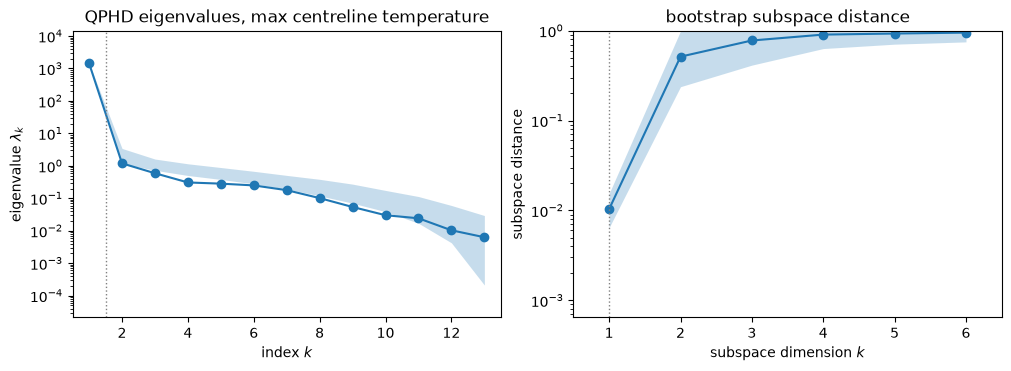

In [9]:
# The dimension of each output, chosen from the eigenvalue ratios and the null test above (see the text).
NCHOSEN = {'fis_gas_produced': 1, 'max_fuel_centerline_temp': 1, 'max_fuel_surface_temp': 2,
           'radial_clad_dia': 1}
subs = {q: ac.with_dimension(subs[q], NCHOSEN[q]) for q in subs}
QC = 'max_fuel_centerline_temp'
s = subs[QC]
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
ac.plotting.plot_eigenvalues(s, ax=axs[0])
ac.plotting.plot_subspace_errors(s, ax=axs[1], k_max=6)
axs[0].set_title('QPHD eigenvalues, max centreline temperature')
axs[1].set_title('bootstrap subspace distance')
ev, bd = s.eigenvalues, s.bootstrap_distances.mean(axis=0)
print('eigenvalues:', ', '.join(f'{v:.3g}' for v in ev[:5]), '...', f'{ev[-1]:.2g}')
print('lambda_k / lambda_k+1, k = 1..4:', ', '.join(f'{ev[k] / ev[k + 1]:.2f}' for k in range(4)))
print('bootstrap mean subspace distance, n = 1..4:', ', '.join(f'{v:.3f}' for v in bd[:4]))
plt.close(fig)
fig

### Results: maximum fuel centreline temperature

The eigenvalues fall from 1.44e+03 to 1.19 after the first ($\lambda_1/\lambda_2$ = 1210.12), and the next
ratios are 2.01, 1.92 and 1.09: no further gap. The bootstrap mean subspace distance is 0.010 for $n = 1$
and 0.514 or more for $n \ge 2$, so only the first direction is well determined.

w1: ax_pow +0.769, porosity +0.534, clad_T +0.310, rough_fuel +0.160, rough_clad +0.031
w2: pellet_h -0.946, clad_T -0.189, rough_fuel -0.145, rough_clad -0.123, porosity +0.100
linear fit: K per input sd, and share of the linear fit variance: ax_pow +29.3 K (0.590), porosity +20.3 K (0.284), clad_T +11.9 K (0.097), rough_fuel +6.2 K (0.027), rough_clad +1.1 K (0.001)


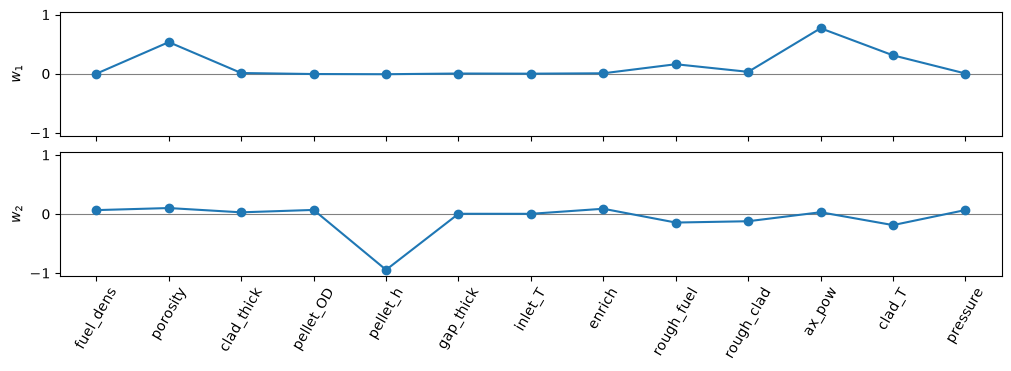

In [10]:
fig, axs = ac.plotting.plot_eigenvectors(s, indices=[0, 1], labels=NAMES, figsize=(10, 3.6))
for ax in axs:
    ax.tick_params(axis='x', labelrotation=60)
for k in range(2):
    w = s.W[:, k]
    print(f'w{k + 1}: ' + ', '.join(f'{NAMES[i]} {w[i]:+.3f}' for i in np.argsort(-np.abs(w))[:5]))
u = np.linalg.lstsq(A1, F[:, 1], rcond=None)[0][1:]          # slopes per sd of each input (K)
share = u**2 / np.sum(u**2)
print('linear fit: K per input sd, and share of the linear fit variance: '
      + ', '.join(f'{NAMES[i]} {u[i]:+.1f} K ({share[i]:.3f})' for i in np.argsort(-share)[:5]))
plt.close(fig)
fig

$w_1$ is dominated by the linear heat rate `ax_pow` (+0.769), the fuel porosity (+0.534) and the cladding surface
temperature (+0.310), with the fuel roughness (+0.160) next; the other nine entries are small. In physical
terms (slopes of the linear fit per input standard deviation): +29.3 K per sd of `ax_pow`, +20.3 K per sd of
porosity, +11.9 K per sd of `clad_T` and +6.2 K per sd of fuel roughness, carrying 0.590, 0.284, 0.097 and
0.027 of the variance of the linear fit. The signs are physical: a higher linear heat rate, a more porous (less conductive)
fuel, a hotter cladding surface and a rougher fuel surface (a lower gap conductance) all raise the
centreline temperature. $w_2$ (pellet height, −0.946) is not determined by QPHD (bootstrap distance 0.514), but its
leading input is the one with a non-smooth effect on this output (below), worth 0.0021 of LOO $R^2$
(0.9967 to 0.9988).

range of the centreline temperature: 229.5 K; sd 37.64 K


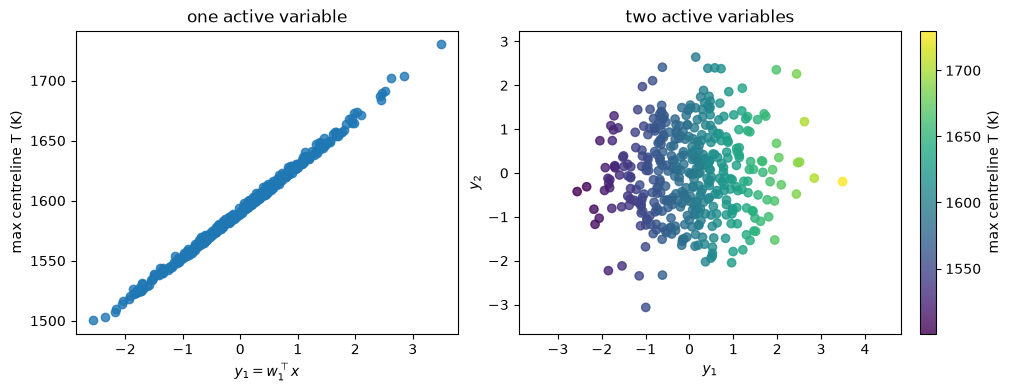

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
ac.plotting.plot_sufficient_summary(s, X=X, f=F[:, 1], dims=1, ax=axs[0], qoi_label='max centreline T (K)')
ac.plotting.plot_sufficient_summary(ac.with_dimension(s, 2), X=X, f=F[:, 1], dims=2, ax=axs[1],
                                    qoi_label='max centreline T (K)')
axs[0].set_title('one active variable')
axs[1].set_title('two active variables')
print(f'range of the centreline temperature: {np.ptp(F[:, 1]):.1f} K; sd {F[:, 1].std(ddof=1):.2f} K')
plt.close(fig)
fig

The one-variable sufficient summary plot is a thin, nearly straight band over the 229.5 K range of the
output; in two active variables the colour changes only along $y_1$. This is the plot of a one-dimensional,
nearly linear function of the 13 inputs over the sampled region.

### Results: maximum fuel surface temperature

The surface temperature is the one output whose structure is not one-dimensional; the cell shows its
eigenvalues and its sufficient summary plots in one and two active variables.

w1: clad_T +0.845, rough_fuel +0.446, ax_pow +0.278, rough_clad +0.076, pellet_h -0.038
w2: pellet_h -0.974, porosity -0.137, fuel_dens +0.094, ax_pow -0.090, pressure +0.070
lambda_k / lambda_k+1, k = 1..4: 19.01, 6.84, 1.04, 1.18
bootstrap mean subspace distance, n = 1..3: 0.060, 0.298, 0.896
linear fit: K per input sd, and share of the linear fit variance: clad_T +6.20 K (0.710), rough_fuel +3.33 K (0.205), ax_pow +2.02 K (0.075), rough_clad +0.54 K (0.005), pellet_h -0.38 K (0.003)


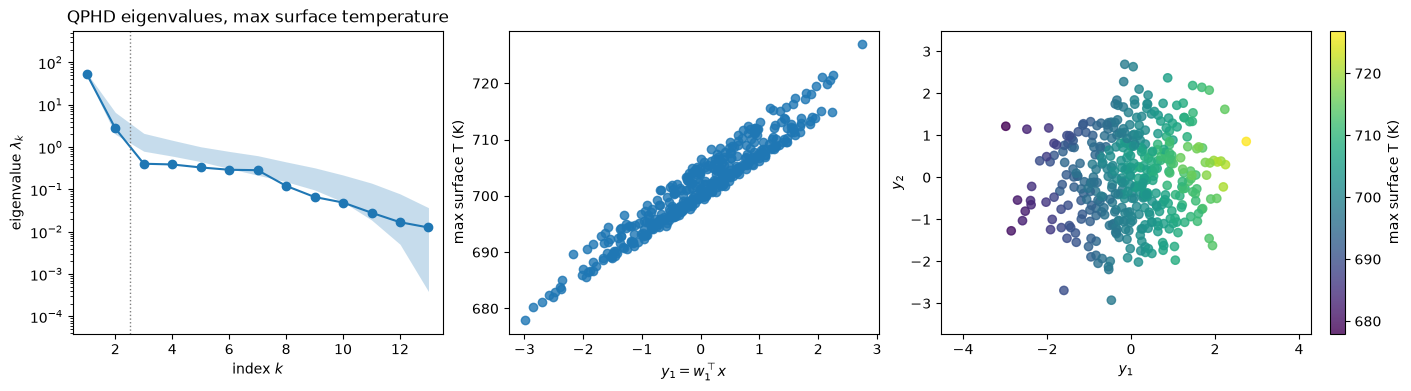

In [12]:
QS = 'max_fuel_surface_temp'
s2 = subs[QS]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
ac.plotting.plot_eigenvalues(s2, ax=axs[0])
axs[0].set_title('QPHD eigenvalues, max surface temperature')
ac.plotting.plot_sufficient_summary(ac.with_dimension(s2, 1), X=X, f=F[:, 2], dims=1, ax=axs[1], qoi_label='max surface T (K)')
ac.plotting.plot_sufficient_summary(ac.with_dimension(s2, 2), X=X, f=F[:, 2], dims=2, ax=axs[2],
                                    qoi_label='max surface T (K)')
for k in range(2):
    w = s2.W[:, k]
    print(f'w{k + 1}: ' + ', '.join(f'{NAMES[i]} {w[i]:+.3f}' for i in np.argsort(-np.abs(w))[:5]))
ev = s2.eigenvalues
print('lambda_k / lambda_k+1, k = 1..4:', ', '.join(f'{ev[k] / ev[k + 1]:.2f}' for k in range(4)))
print('bootstrap mean subspace distance, n = 1..3:',
      ', '.join(f'{v:.3f}' for v in s2.bootstrap_distances.mean(axis=0)[:3]))
u = np.linalg.lstsq(A1, F[:, 2], rcond=None)[0][1:]
share = u**2 / np.sum(u**2)
print('linear fit: K per input sd, and share of the linear fit variance: '
      + ', '.join(f'{NAMES[i]} {u[i]:+.2f} K ({share[i]:.3f})' for i in np.argsort(-share)[:5]))
plt.close(fig)
fig

$w_1$ is led by the cladding surface temperature (+0.845), then the fuel roughness (+0.446) and the axial
power (+0.278); the linear fit gives +6.20 K, +3.33 K and +2.02 K per standard deviation, with variance shares
0.710, 0.205 and 0.075. The porosity, second for the centreline temperature, does not appear among the top
five. $w_2$ is almost the pellet height alone (−0.974), with a bootstrap subspace distance of 0.298 for
$n = 2$ against 0.060 for $n = 1$: the second direction is resolved but less sharply than the first. The
one-variable plot shows a band of roughly constant width around a straight line, wider than for the
centreline temperature relative to the range; in two variables the colour changes along $y_1$, with a lower
temperature at both ends of $y_2$. The next cell looks at the pellet height directly.

QoI                        linear  + z_h^2  + g(z_h), piecewise linear
fis_gas_produced           0.9992   0.9992                      0.9992
max_fuel_centerline_temp   0.9967   0.9970                      0.9988
max_fuel_surface_temp      0.9181   0.9346                      0.9839
radial_clad_dia            0.9966   0.9967                      0.9966
surface temperature, linear + z_h^2: coefficient of z_h -0.388 K, of z_h^2 -0.720 K
surface temperature: share of the variance left by the piecewise-linear fit 0.0161; by the linear fit 0.0819
max surface temperature: residual sd 2.15 K; mean residual (K) in bins of z_h of width 0.2 from -1.6 to 1.2: -2.5 -2.5 -2.0 -0.9 +1.6 +2.9 +3.1 +2.4 +1.4 -0.1 -1.2 -1.4 -1.4 -1.4
   pellet height at z_h = -0.8: 0.01328 m; at z_h = 0.4: 0.01400 m
max centreline temperature: residual sd 2.09 K; mean residual (K) in bins of z_h of width 0.2 from -1.6 to 1.2: -2.2 -1.9 -1.8 -0.2 +1.7 +2.9 +2.7 +1.4 +0.5 -0.9 -1.0 -1.2 -0.9 -1.0
   pellet height at z_h 

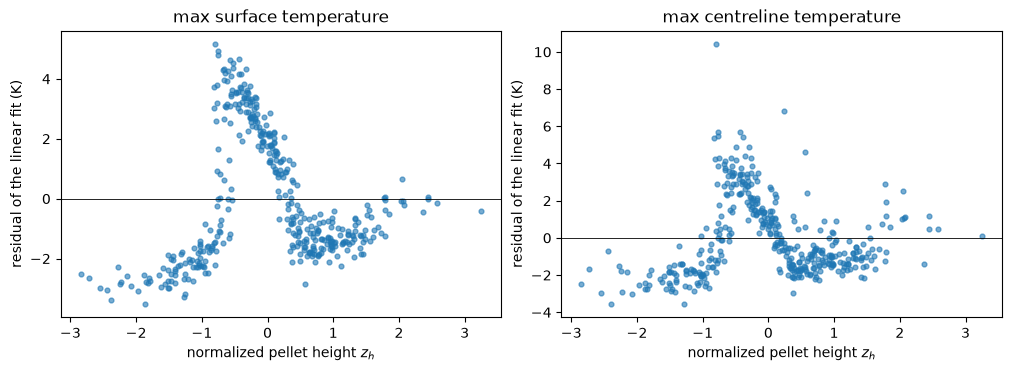

In [13]:
# What the second direction of the surface temperature is: the residuals of the linear fit against the
# normalized pellet height (left: surface, right: centreline temperature), and two fits that add a pellet-height
# term to the linear fit: its square, and a piecewise-linear function of it (20 hat functions with knots at
# the quantiles of z_h, this notebook's choice), with the other 12 inputs linear. Exact LOO R^2 throughout.
ih = NAMES.index('pellet_h')
zh = Z[:, ih]
KNOTS = np.quantile(zh, np.linspace(0, 1, 20))
HATS = np.column_stack([np.interp(zh, KNOTS, np.eye(len(KNOTS))[k]) for k in range(len(KNOTS))])
A1h = np.column_stack([A1, zh**2])
Apl = np.column_stack([np.delete(Z, ih, axis=1), HATS])   # the hat functions sum to 1: intercept included
ADD = {}
print(f"{'QoI':25s} {'linear':>7s} {'+ z_h^2':>8s} {'+ g(z_h), piecewise linear':>27s}")
for j, (q, _, _) in enumerate(QOIS):
    g = F[:, j]
    ADD[q] = fit_r2(Apl, g)[1]
    print(f'{q:25s} {fit_r2(A1, g)[1]:7.4f} {fit_r2(A1h, g)[1]:8.4f} {ADD[q]:27.4f}')
c = np.linalg.lstsq(A1h, F[:, 2], rcond=None)[0]
print(f'surface temperature, linear + z_h^2: coefficient of z_h {c[1 + ih]:+.3f} K, of z_h^2 {c[-1]:+.3f} K')
print(f"surface temperature: share of the variance left by the piecewise-linear fit {1 - ADD[QS]:.4f}; "
      f"by the linear fit {1 - fit_r2(A1, F[:, 2])[1]:.4f}")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for ax, j, title in ((axs[0], 2, 'max surface temperature'), (axs[1], 1, 'max centreline temperature')):
    r = F[:, j] - Q1 @ (Q1.T @ F[:, j])
    ax.scatter(zh, r, s=12, alpha=0.6)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xlabel('normalized pellet height $z_h$')
    ax.set_ylabel('residual of the linear fit (K)')
    ax.set_title(title)
    edges = np.arange(-1.6, 1.21, 0.2)
    idx = np.digitize(zh, edges)
    means = [r[idx == b].mean() if np.any(idx == b) else np.nan for b in range(1, len(edges))]
    print(f'{title}: residual sd {r.std(ddof=1):.2f} K; mean residual (K) in bins of z_h of width 0.2 from '
          f'{edges[0]:.1f} to {edges[-1]:.1f}: ' + ' '.join(f'{v:+.1f}' for v in means))
    print(f'   pellet height at z_h = -0.8: {mu[ih] - 0.8 * sd[ih]:.5f} m; at z_h = 0.4: {mu[ih] + 0.4 * sd[ih]:.5f} m')
plt.close(fig)
fig

The pellet height acts through a non-smooth function. Against $z_h$ the residuals of the linear fit rise
and fall once for both temperatures. For the surface temperature the bin
means are −2.5 K to −0.9 K up to $z_h = -0.8$ (pellet height 0.01328 m), +1.6 K in the next bin, a peak of
+3.1 K, and −1.2 K to −1.4 K from $z_h = 0.4$ (0.01400 m) on. The centreline temperature has the same shape
(−0.2 K to +1.7 K across $z_h = -0.8$, peak +2.9 K). A square term captures little of it (LOO $R^2$ 0.9181 to
0.9346 for the surface temperature; coefficients −0.388 K for $z_h$ and −0.720 K for $z_h^2$). A fit linear in
the other 12 inputs plus a piecewise-linear function of $z_h$ (20 knots at quantiles of $z_h$, this notebook's
choice) reaches 0.9839 (surface; 0.0161 of the variance left against 0.0819 for the linear fit) and 0.9988
(centreline). The fission gas (0.9992) and the displacement (0.9966) do not change.

The next cell describes the pellet-height term more closely for the surface temperature: fits that add to the linear fit one step in the pellet height, a step with a change
of slope, or two steps (a raised window), with the step positions chosen by exact LOO $R^2$ over the stored
pellet heights (two steps on every third stored value). It then takes the rows with pellet heights from 13.25 to
13.45 mm, near the lower edge of the window, and labels a row "high" when its residual from the linear part of
the window fit (fitted on the rows outside that band) exceeds half the step (this notebook's rule). Each input of
the high and low rows is compared by a Mann–Whitney test. If the jump were set by pellet height alone, the band
would not mix the two states.

In [14]:
hz = X[:, ih]
g = F[:, 2]
cand = np.unique(hz)[5:-5]
one = max((fit_r2(np.column_stack([A1, hz > c]), g)[1], c) for c in cand)
slope = max((fit_r2(np.column_stack([A1, hz > c, (hz > c) * (hz - c)]), g)[1], c) for c in cand)
c3 = cand[::3]
two = max((fit_r2(np.column_stack([A1, hz > a, hz > b]), g)[1], a, b) for k, a in enumerate(c3) for b in c3[k + 1:])
print(f'surface temperature, exact LOO R^2: linear {fit_r2(A1, g)[1]:.4f}; one step at {one[1] * 1e3:.3f} mm '
      f'{one[0]:.4f}; step + slope change at {slope[1] * 1e3:.3f} mm {slope[0]:.4f}; two steps at '
      f'{two[1] * 1e3:.3f} and {two[2] * 1e3:.3f} mm {two[0]:.4f}; piecewise linear (20 knots) {ADD[QS]:.4f}')
print(f'LOO R^2 gain of the piecewise-linear pellet-height term over the linear fit: {ADD[QS] - fit_r2(A1, g)[1]:.4f}')
win = (hz > two[1]) & (hz <= two[2])
band = (hz >= 0.01325) & (hz <= 0.01345)
Aw = np.column_stack([A1, win])
cw = np.linalg.lstsq(Aw[~band], g[~band], rcond=None)[0]
high = band & (g - A1 @ cw[:-1] > cw[-1] / 2)
low = band & ~high
print(f'window step (fitted outside the band): {cw[-1]:.2f} K; rows in 13.25-13.45 mm: {int(band.sum())}, '
      f'high: {int(high.sum())}')
print('high minus low rows in the band, mean of z (sd units) and Mann-Whitney p, inputs with p < 0.1: '
      + ', '.join(f'{NAMES[i]} {Z[high, i].mean() - Z[low, i].mean():+.2f} (p = {stats.mannwhitneyu(Z[high, i], Z[low, i]).pvalue:.3g})'
                  for i in range(m) if stats.mannwhitneyu(Z[high, i], Z[low, i]).pvalue < 0.1))
o = np.argsort(hz[band])
print('states in the band sorted by pellet height (H high, l low): ' + ''.join('H' if v else 'l' for v in high[band][o]))

surface temperature, exact LOO R^2: linear 0.9181; one step at 13.256 mm 0.9628; step + slope change at 13.256 mm 0.9668; two steps at 13.252 and 13.923 mm 0.9783; piecewise linear (20 knots) 0.9839
LOO R^2 gain of the piecewise-linear pellet-height term over the linear fit: 0.0659
window step (fitted outside the band): 3.97 K; rows in 13.25-13.45 mm: 53, high: 35
high minus low rows in the band, mean of z (sd units) and Mann-Whitney p, inputs with p < 0.1: porosity +0.72 (p = 0.0225), rough_fuel +0.81 (p = 0.0179), rough_clad -0.59 (p = 0.0496), ax_pow +0.91 (p = 0.000653), clad_T +0.63 (p = 0.0236)
states in the band sorted by pellet height (H high, l low): llHlHlHllHHHHHlHHHHlHlHllHlHHHHHHHHHllHlHlHHHHHlHHlHH


A single step at 13.256 mm already raises the LOO $R^2$ of the surface temperature from 0.9181 to 0.9628
(0.9668 with a change of slope). Two steps, up at 13.252 mm and down at 13.923 mm, give 0.9783, a raised window
of pellet heights about 4 K high (3.97 K fitted outside the band). The 20-knot piecewise-linear term reaches
0.9839. The lower edge of the window is **not a function of pellet height alone**. Of the 53 rows between 13.25
and 13.45 mm, 35 are in the high state by the rule above, and the states alternate along the pellet height (last
line). The high rows have a higher linear heat rate (+0.91 sd, p = 0.000653), fuel roughness (+0.81 sd,
p = 0.0179), porosity (+0.72 sd, p = 0.0225) and cladding temperature (+0.63 sd, p = 0.0236), and a lower
cladding roughness (−0.59 sd, p = 0.0496). These are the inputs that raise the fuel temperature, so the edge is a
surface in (pellet height, power, porosity, roughness, cladding temperature). That points to a
temperature-dependent switch in the runs, such as a threshold of a material or gap model or a jump in where the
maximum sits. An axial-mesh effect set by the pellet height alone would not depend on the other inputs, so it
does not explain this mixing. The cause is not known: the BISON input files were not published.

The paper has two related statements (p. 27). Its Morris screening finds that "the pellet height sensitivity
in fuel surface temperature has large σ in its EEs as µ and µ* have different values", which fits a
non-monotone effect. Its Sobol' indices, from the DeepGP surrogate, give the surface temperature
"insignificant effect from the pellet height". Here the piecewise-linear pellet-height term adds 0.0659 to the
LOO $R^2$, so the stored runs and the paper's Sobol' result disagree on this point. The DeepGP's lowest
validation $Q^2$, 0.933 for the surface temperature (Table 8, p. 26), is consistent with a surrogate that misses
this term. The active subspace describes the smooth part; the pellet height enters $w_2$ of both temperatures
because of this term.

fis_gas_produced          w1: pellet_h +0.899, ax_pow +0.438, pellet_OD +0.003, clad_T -0.002;  bootstrap distance n = 1: 0.004
max_fuel_centerline_temp  w1: ax_pow +0.769, porosity +0.534, clad_T +0.310, rough_fuel +0.160;  bootstrap distance n = 1: 0.010
max_fuel_surface_temp     w1: clad_T +0.845, rough_fuel +0.446, ax_pow +0.278, rough_clad +0.076;  bootstrap distance n = 1: 0.060
radial_clad_dia           w1: ax_pow +0.757, clad_T +0.455, porosity +0.416, rough_fuel +0.200;  bootstrap distance n = 1: 0.010


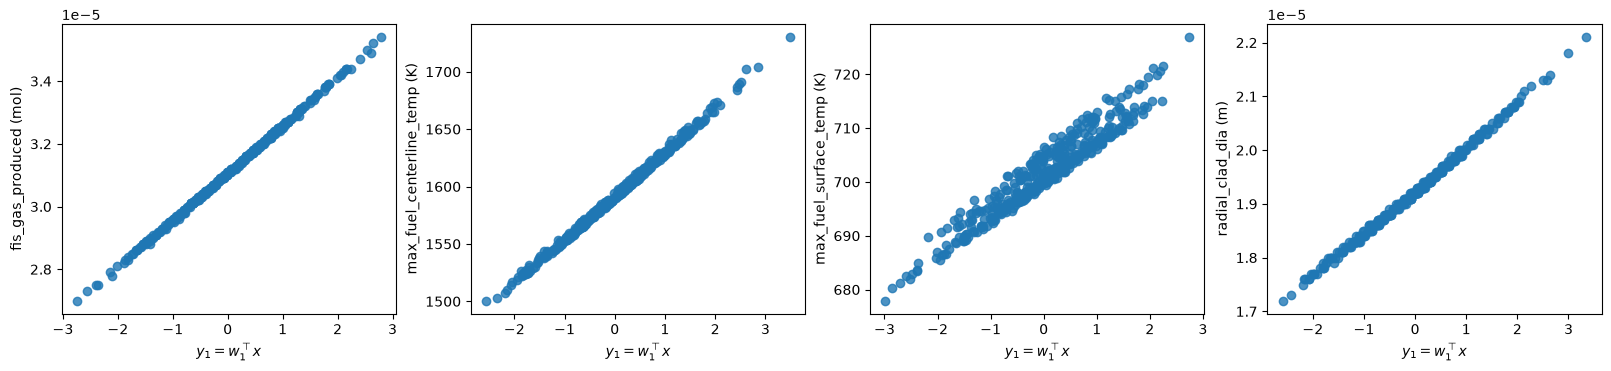

In [15]:
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True)
for j, (q, d, u) in enumerate(QOIS):
    ac.plotting.plot_sufficient_summary(ac.with_dimension(subs[q], 1), X=X, f=F[:, j], dims=1, ax=axs[j], qoi_label=f'{q} ({u})')
    w = subs[q].W[:, 0]
    print(f'{q:25s} w1: ' + ', '.join(f'{NAMES[i]} {w[i]:+.3f}' for i in np.argsort(-np.abs(w))[:4])
          + f';  bootstrap distance n = 1: {subs[q].bootstrap_distances[:, 0].mean():.3f}')
plt.close(fig)
fig

### All four outputs: one active variable

Each output's $w_1$ is sharply determined (bootstrap distance 0.004–0.060). The fission gas depends on the pellet height (+0.899) and the linear heat rate (+0.438) only; the displacement on the same inputs as the
centreline temperature, in a different mix (linear heat rate +0.757, cladding temperature +0.455, porosity +0.416,
fuel roughness +0.200); the surface temperature mostly on the cladding temperature.

In [16]:
# Fission gas: a power law in pellet height and linear heat rate? Least squares of log f on log x (all 13 inputs).
L = np.column_stack([np.ones(M), np.log(X)])
c, *_ = np.linalg.lstsq(L, np.log(F[:, 0]), rcond=None)
print('exponents of log(fis_gas_produced) on log(input): '
      + ', '.join(f'{NAMES[i]} {c[1 + i]:+.3f}' for i in np.argsort(-np.abs(c[1:]))[:4]))
print(f'exact LOO R^2 of this log-log linear fit: {fit_r2(L, np.log(F[:, 0]))[1]:.4f}')
w = subs['fis_gas_produced'].W[:, 0]
ih, ia = NAMES.index('pellet_h'), NAMES.index('ax_pow')
print(f'w1 entries pellet_h / ax_pow = {w[ih] / w[ia]:.3f}; relative sd pellet_h / ax_pow = '
      f'{(sd[ih] / mu[ih]) / (sd[ia] / mu[ia]):.3f}')

exponents of log(fis_gas_produced) on log(input): ax_pow +1.000, pellet_h +1.000, pellet_OD +0.106, enrich -0.035
exact LOO R^2 of this log-log linear fit: 0.9996
w1 entries pellet_h / ax_pow = 2.053; relative sd pellet_h / ax_pow = 2.048


The fission gas follows a power law: regressed in logarithms on all 13 inputs, its exponents are +1.000 for
both `ax_pow` and `pellet_h`, the next one +0.106 (`pellet_OD`), with LOO $R^2$ 0.9996 (the stored rounding
allows about 0.9996). The fission gas produced is thus proportional to (pellet height) × (linear heat rate), as
for a production proportional to the energy generated in a rod of 10 pellets at a given linear heat rate.
This explains the two entries of $w_1$: their ratio, 2.053, equals the ratio of the relative standard
deviations of the two inputs, 2.048. The product is not linear in the two inputs, which is the small but
resolved second direction found above.

## Surrogate on the active variables

A quadratic polynomial in the chosen active variables (`ac.fit_surrogate(kind='poly', degree=2)`), with its
exact LOO $R^2$; for comparison the same in one active variable, and the linear fit in all 13 inputs.

In [17]:
SUR = {}
print(f"{'QoI':25s} {'n':>2s} {'LOO R2, poly deg 2 on n active variables':>41s} {'(n = 1)':>8s} {'lin LOO, 13 inputs':>19s}")
for j, (q, _, _) in enumerate(QOIS):
    n = NCHOSEN[q]
    sur = ac.fit_surrogate(X=X, f=F[:, j], subspace=ac.with_dimension(subs[q], n), kind='poly', degree=2)
    sur1 = ac.fit_surrogate(X=X, f=F[:, j], subspace=ac.with_dimension(subs[q], 1), kind='poly', degree=2)
    SUR[q] = sur.loo_r_squared
    print(f'{q:25s} {n:2d} {sur.loo_r_squared:41.4f} {sur1.loo_r_squared:8.4f} {FITS[q][1]:19.4f}')
print(f"surface temperature: variance share not explained by the 2-D surrogate (LOO) {1 - SUR[QS]:.4f}")

QoI                        n  LOO R2, poly deg 2 on n active variables  (n = 1)  lin LOO, 13 inputs
fis_gas_produced           1                                    0.9994   0.9994              0.9992
max_fuel_centerline_temp   1                                    0.9973   0.9973              0.9967
max_fuel_surface_temp      2                                    0.9401   0.9213              0.9181
radial_clad_dia            1                                    0.9978   0.9978              0.9966
surface temperature: variance share not explained by the 2-D surrogate (LOO) 0.0599


In one active variable the quadratic has LOO $R^2$ 0.9994 (fission gas), 0.9973 (centreline temperature) and
0.9978 (displacement): as good as the linear and quadratic fits in all 13 inputs (0.9992, 0.9967, 0.9966
linear). For the surface temperature, two active variables give 0.9401 against 0.9213 for one, and the full
13-input quadratic gives only 0.9197 (0.0599 of the variance is left by the 2-D surrogate; the additive
pellet-height fit above leaves 0.0161). These LOO values keep the subspace fixed at its full-data estimate; the
next cell refits the subspace in each fold.

In [18]:
# The surrogate LOO above keeps W fixed (fitted on all rows). A check that refits the subspace in each fold:
# 10-fold cross-validation in which QPHD and the polynomial are both refitted on the training rows.
rng = np.random.default_rng(SEED)
folds = np.array_split(rng.permutation(M), 10)
for j, (q, _, _) in enumerate(QOIS):
    n = NCHOSEN[q]
    pred = np.empty(M)
    for te in folds:
        tr = np.setdiff1d(np.arange(M), te)
        st = ac.active_subspace(space=space, X=X[tr], f=F[tr, j], estimator='qphd', n=n)
        sur = ac.fit_surrogate(X=X[tr], f=F[tr, j], subspace=st, kind='poly', degree=2)
        pred[te] = ac.predict(sur, X[te])
    f = F[:, j]
    cv = 1 - np.sum((f - pred)**2) / np.sum((f - f.mean())**2)
    print(f'{q:25s} n = {n}: 10-fold CV R^2 with the subspace refitted in each fold '
          f'{cv:.4f} (fixed-subspace LOO minus CV: {SUR[q] - cv:+.4f})')

fis_gas_produced          n = 1: 10-fold CV R^2 with the subspace refitted in each fold 0.9993 (fixed-subspace LOO minus CV: +0.0000)
max_fuel_centerline_temp  n = 1: 10-fold CV R^2 with the subspace refitted in each fold 0.9971 (fixed-subspace LOO minus CV: +0.0001)


max_fuel_surface_temp     n = 2: 10-fold CV R^2 with the subspace refitted in each fold 0.9323 (fixed-subspace LOO minus CV: +0.0078)
radial_clad_dia           n = 1: 10-fold CV R^2 with the subspace refitted in each fold 0.9976 (fixed-subspace LOO minus CV: +0.0001)


With QPHD refitted in each of 10 folds, the cross-validated $R^2$ is 0.9993, 0.9971, 0.9323 and 0.9976:
within 0.0001 of the fixed-subspace LOO values, and lower by 0.0078 for the surface temperature, whose
second direction is the least precisely estimated.

## Comparison with the paper

Page and table numbers are those of the accepted manuscript. The paper fits DeepGP surrogates to 300 runs and
computes Morris and Sobol' sensitivities from them; it reports no active subspace.

| quantity | paper (page) | this notebook |
|---|---|---|
| model and case | BISON, PCMI benchmark Case 1, 10-pellet rod ramped to 40 kW/m (Sect. 3.4, p. 15) | the stored runs |
| inputs, outputs | 13 inputs (p. 15, Table 2, p. 16), 4 outputs at the last time step (p. 16) | 13, 4 |
| input distribution | independent normal, sd = Table 2 relative value × benchmark nominal (p. 15; nominal not printed) | normal (KS p against uniform ≤ 2.9e-13); sample sd/mean within 1.82 standard errors of Table 2; sample moments used |
| support | ±3σ "is the support of the samples" (p. 27) | samples reach 3.66σ (porosity), 3.64σ (`ax_pow`) in Table 2 sd |
| number of runs | 200 training + 100 validation (Table 3, p. 18) | 400 stored rows (pyMAISE); which 300 the paper used is not known |
| output mean (sd/mean) | 3.1e-5 mol (4.8 %), 1591.6 K (2.4 %), 701.8 K (1.1 %), 1.92e-5 m (4.2 %) (p. 26) | 3.1069e-05 (4.80 %), 1591.6 (2.36 %), 701.75 (1.11 %), 1.9234e-05 (4.20 %) (all 400 rows) |
| surrogate accuracy | DeepGP $Q^2$ on 100 validation runs: 0.987, 0.986, 0.933, 0.978 (Table 8, p. 26) | quadratic on the active variables, LOO $R^2$ (W fixed): 0.9994, 0.9973, 0.9401 ($n = 2$), 0.9978; 10-fold CV (W refitted): 0.9993, 0.9971, 0.9323, 0.9976; a different validation |
| fission gas | pellet height and LHR "contribute to more than 98 %" of the variance (Sobol', p. 27) | $w_1$: `pellet_h` +0.899, `ax_pow` +0.438; power law with exponents +1.000, +1.000 |
| centreline temperature | Morris: porosity, roughness, LHR, cladding surface temperature (p. 27); Sobol' agrees | $w_1$: `ax_pow` +0.769, porosity +0.534, `clad_T` +0.310, fuel roughness +0.160 |
| surface temperature | "controlled by the clad surface temperature, fuel roughness, and LHR, with insignificant effect from the pellet height" (Sobol', p. 27) | `clad_T` 0.710, fuel roughness 0.205, `ax_pow` 0.075 of the linear-fit variance; pellet-height term adds 0.0659 to the LOO $R^2$ |
| radial cladding displacement | controlled by parameters similar to the centreline temperature (p. 27) | $w_1$: `ax_pow` +0.757, `clad_T` +0.455, porosity +0.416, fuel roughness +0.200 |
| active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2$ = 1210.1 (centreline); $n = 2$, 19.0 and 6.84 (surface) |

The leading inputs agree with the paper for every output. For the surface temperature, the paper names the
same three inputs that lead $w_1$ and the linear fit here (cladding temperature, fuel roughness, LHR). The one
disagreement is the pellet height. The paper's Sobol' indices find it insignificant for the surface temperature,
while the stored runs carry a non-smooth pellet-height term that adds 0.0659 to the LOO $R^2$ and forms the
second active direction.

## References

- M. I. Radaideh, T. Kozlowski. Surrogate modeling of advanced computer simulations using deep Gaussian
  processes. *Reliability Engineering & System Safety* 195:106731, 2020.
  [doi:10.1016/j.ress.2019.106731](https://doi.org/10.1016/j.ress.2019.106731) (page numbers in this notebook are
  those of the authors' accepted manuscript).
- R. L. Williamson, J. D. Hales, S. R. Novascone, M. R. Tonks, D. R. Gaston, C. J. Permann, D. Andrs,
  R. C. Martineau. Multidimensional multiphysics simulation of nuclear fuel behavior. *Journal of Nuclear
  Materials* 423(1–3):149–163, 2012. [doi:10.1016/j.jnucmat.2012.01.012](https://doi.org/10.1016/j.jnucmat.2012.01.012)
- G. Rossiter, S. Massara, M. Amaya. OECD/NEA benchmark on pellet-clad mechanical interaction modelling with
  fuel performance codes. Technical report, Atomic Energy of Canada Limited, 2016.
- pyMAISE 0.0.2, Michigan Artificial Intelligence Standard Environment (P. Myers et al.), PyPI, Apache
  License 2.0; source https://github.com/aims-umich/pyMAISE.
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

## Acknowledgments

The paper's work was supported by the U.S. Department of Energy under award DE-NE0008573, through the Nuclear
Energy University Program (NEUP). The authors also thank the colleagues who developed the "PinToPerform"
templates used to generate the BISON input file (p. 30).

In [19]:
print(f'notebook run time: {time.perf_counter() - t_start:.0f} s')

notebook run time: 22 s
